[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/kulinskij-tech/ClassMech/blob/main/ClassMech_Python/classmech_eom.ipynb)


# Integration of the Euler–Lagrange equations: conservation laws and symmetries

In [1]:
import numpy as np
import sympy as sp
import matplotlib.pyplot as plt
import ipywidgets as widgets
from IPython.display import display


def animate_parameter(draw,minimum,maximum,value,step,label):
    draw(value)
    slider=widgets.FloatSlider(value=value,min=minimum,max=maximum,step=step,
                               description=label,continuous_update=False)
    play=widgets.Play(value=0,min=0,max=int(round((maximum-minimum)/step)),step=1,interval=120,repeat=False)
    def advance(change):
        slider.value=min(maximum,minimum+change['new']*step)
    play.observe(advance,names='value')
    view=widgets.interactive_output(lambda parameter: draw(parameter),{'parameter':slider})
    display(widgets.VBox([widgets.HBox([play,slider]),view]))
    return slider,play,view

In general, the equations of motion

$$
m\frac{{d}^{2}\mathbf{r}}{{dt}^{2}}=\mathbf{F}\tag{1}
$$

cannot be integrated analytically. For bounded motion, however, the virial theorem gives a useful general result:

$$
m\mathbf{ }\mathbf{r}\frac{{d}^{2}\mathbf{r}}{{dt}^{2}}=m\frac{d}{dt}\left(\mathbf{r}\frac{d\mathbf{r}}{dt}\right)- m {\mathbf{v}}^{2}=\mathbf{r\cdot F}\mathbf{\Rightarrow }\mathbf{ }\frac{m {\mathbf{v}}^{2}}{2}=\frac{1}{2}m\frac{d}{dt}\left(\mathbf{r}\frac{d\mathbf{r}}{dt}\right)-\frac{1}{2}\mathbf{r\cdot F}\tag{2}
$$

For bounded motion, the long-time average satisfies

$$
\frac{1}{T}{\int }_{0}^{T}\frac{m {\mathbf{v}}^{2}}{2}dt=\left\langle \frac{m {\mathbf{v}}^{2}}{2}\right\rangle =\left\langle \frac{1}{2}m\frac{d}{dt}\left(\mathbf{r}\frac{d\mathbf{r}}{dt}\right)\right\rangle -\left\langle \frac{1}{2}\mathbf{r\cdot F}\right\rangle ,\left\langle \frac{m {\mathbf{v}}^{2}}{2}\right\rangle =-\frac{1}{2}\left\langle \mathbf{r\cdot F}\right\rangle \tag{3}
$$

If the force derives from a homogeneous potential, $\mathbf{F}=-\nabla U$, with

$$
U\left(\lambda  \mathbf{r}\right)={\lambda }^{n}U\left(\mathbf{r}\right)\tag{4}
$$

Euler’s theorem gives

$$
\mathbf{r}\cdot \nabla U\left(r\right)=n U\left(\mathbf{r}\right)\tag{5}
$$

and relates the total energy to the time averages of its kinetic and potential parts:

$$
\left\langle \frac{m {\mathbf{v}}^{2}}{2}\right\rangle =\frac{n}{2}\left\langle U\right\rangle \Rightarrow \left\langle U\right\rangle =\frac{2}{n+2}E,\left\langle \frac{m {\mathbf{v}}^{2}}{2}\right\rangle =\frac{n}{n+2}E\tag{6}
$$

Another directly integrable case is motion under a prescribed time-dependent force:

$$
\frac{{d}^{2}\mathbf{r}}{{dt}^{2}}=\mathbf{f}\left(t\right)\Rightarrow \mathbf{v}\left(t\right)={\mathbf{v}}_{0}+{\int }_{0}^{t}f\left(t'\right)dt'\\ \mathbf{r}\left(t\right)={\mathbf{r}}_{0}+{\mathbf{v}}_{0}t+{\int }_{0}^{t}{dt}_{2}{\int }_{0}^{{t}_{2}}f\left({t}_{1}\right){dt}_{1}\tag{7}
$$

Many mechanical systems require numerical integration. In special cases, enough conserved quantities allow the equations to be integrated analytically, or reduced to quadratures. If the Lagrangian is independent of a coordinate, its conjugate momentum is conserved:

$$
\frac{d}{dt}\left(\frac{\partial L}{\partial  {\dot{q}}_{i}}\right)=0\Rightarrow {p}_{i}=\frac{\partial L}{\partial  {\dot{q}}_{i}}=\text{const}\tag{8}
$$

For an angular coordinate, the conjugate momentum is an angular momentum.

$$
\frac{d}{dt}L\left(t,q,\dot{q}\right)=\frac{\partial L}{\partial t}+\dot{q}\frac{\partial L}{\partial q}+\ddot{q}\frac{\partial L}{\partial \dot{q}}\\ \frac{d}{dt}\left({\dot{q}}^{i}\frac{\partial L}{\partial {\dot{q}}^{i}}-L\right)=-\frac{\partial L}{\partial t}\tag{9}
$$

If the Lagrangian has no explicit time dependence, $L=L\left(q,\dot q\right)$:

$$
\frac{d}{dt}\left(\frac{\partial L}{\partial  {\dot{q}}_{i}}\right)-\frac{\partial L}{\partial  {q}_{i}}=0\Rightarrow {\sum }_{i}^{n}{\dot{q}}_{i}\frac{d}{dt}\left(\frac{\partial L}{\partial  {\dot{q}}_{i}}\right)-{\sum }_{i}^{n}{\dot{q}}_{i}\frac{\partial L}{\partial  {q}_{i}}=\frac{d}{dt}\left({\sum }_{i}^{n}{\dot{q}}_{i}\frac{\partial L}{\partial  {\dot{q}}_{i}}\right)-{\sum }_{i}^{n}\left({\ddot{q}}_{i}\frac{\partial L}{\partial  {\dot{q}}_{i}}+{\dot{q}}_{i}\frac{\partial L}{\partial  {q}_{i}}\right)=\frac{d}{dt}\left({\dot{q}}_{i}\frac{\partial L}{\partial  {\dot{q}}_{i}}-L\right)=0\tag{10}
$$

the energy is conserved:

$$
E={\sum }_{i}^{n}{\dot{q}}_{i}\frac{\partial L}{\partial  {\dot{q}}_{i}}-L=\text{const}\tag{11}
$$

These examples suggest a general relation between continuous symmetries of the Lagrangian and conserved quantities. Noether’s theorem expresses this relation and plays a central role throughout physics.

Every continuous one-parameter coordinate transformation that leaves the Lagrangian invariant

$$
\widetilde{q}=Q\left(q\left(t\right),\varepsilon \right) = q+\varepsilon  \Theta +o\left(\varepsilon \right)\\ \left.\frac{d}{d\varepsilon }L\left(t,\widetilde{q},\overset{\dot{~}}{q}\right)\right|_{\varepsilon =0}=\frac{\partial L}{\partial  q}\theta +\frac{\partial L}{\partial  \dot{q}}\frac{d\theta }{dt}=0\tag{12}
$$

maps solutions to solutions and gives a conserved quantity:

$$
\frac{d}{dt}\left(\frac{\partial L}{\partial  \dot{q}}\right)-\frac{\partial L}{\partial  q}=0\Rightarrow \frac{d}{dt}\left(\frac{\partial L}{\partial  \dot{q}}\right)\theta +\frac{\partial L}{\partial  \dot{q}}\dot{\theta }=\frac{d}{dt}\left(\frac{\partial L}{\partial  \dot{q}}\theta \right)=0\Rightarrow \frac{\partial L}{\partial  \dot{q}}\theta =\text{const}\tag{13}
$$

For a translation, $\Theta=1$, this reproduces momentum conservation.

For a transformation of the time variable:

$$
t=\widetilde{t}+\varepsilon  \tau +o\left(\varepsilon \right), S = \int L dt = \int L \frac{dt}{d\widetilde{t}}d\widetilde{t} \\ \frac{dq}{dt}=\frac{dq}{d \widetilde{t}}\frac{d\widetilde{t}}{dt}=\frac{dq}{d\widetilde{t}}\left(1+\varepsilon  \frac{d\tau }{dt}\right)+o\left(\varepsilon \right)\\ \left.\frac{d}{d\varepsilon }\left(L\left(t,q,\frac{dq}{d\widetilde{t}}\frac{d\widetilde{t}}{dt}\right)\frac{dt}{d\widetilde{t}}\right)\right|_{\varepsilon =0}=\frac{dL}{d \varepsilon }-L\frac{d\tau }{d \widetilde{t}}=\tau \frac{\partial L}{\partial \widetilde{t}}-\dot{q}\frac{\partial L}{\partial \dot{q}}\frac{d\tau }{d \widetilde{t}}+L\frac{d\tau }{d \widetilde{t}}=0\tag{14}
$$

$$
\tau \frac{d}{d \widetilde{t}}\left({\dot{q}}^{i}\frac{\partial L}{\partial {\dot{q}}^{i}}-L\right)+\tau \frac{\partial L}{\partial \widetilde{t}}=0\tag{15}
$$

we obtain

$$
\frac{d}{d t}\left(\left({\dot{q}}^{i}\frac{\partial L}{\partial {\dot{q}}^{i}}-L\right)\tau \right)=0\Rightarrow \left({\dot{q}}^{i}\frac{\partial L}{\partial {\dot{q}}^{i}}-L\right)\tau  = \text{const}\tag{16}
$$

For $\tau=1$, this reproduces energy conservation.

## One-dimensional systems

A one-dimensional conservative system

$$
m\ddot{x}=-U'\left(x\right)\Rightarrow {\left(\frac{dx}{dt}\right)}^{2}=\frac{2}{m}\left(E-U\left(x\right)\right)\tag{17}
$$

can be integrated using energy conservation in the region where $E\ge U$:

$$
t=\overset{x}{\underset{{x}_{0}}{\int }}\frac{ds}{\sqrt{\frac{2}{m}\left(E-U\left(s\right)\right)}}\tag{18}
$$

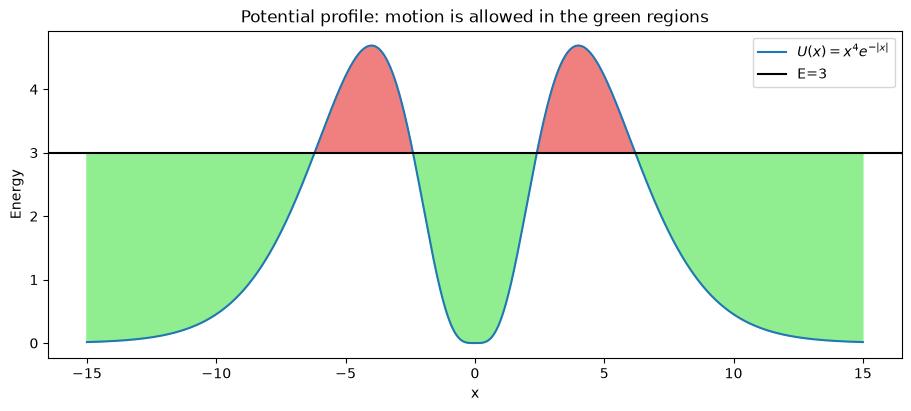

In [2]:
xgrid=np.linspace(-15,15,1501)
U=xgrid**4*np.exp(-np.abs(xgrid)); E=3.0
fig,ax=plt.subplots(figsize=(9,4),layout='constrained')
ax.plot(xgrid,U,label=r'$U(x)=x^4 e^{-|x|}$'); ax.axhline(E,color='black',label='E=3')
ax.fill_between(xgrid,U,E,where=U<=E,color='lightgreen',interpolate=True)
ax.fill_between(xgrid,U,E,where=U>E,color='lightcoral',interpolate=True)
ax.set(xlabel='x',ylabel='Energy',title='Potential profile: motion is allowed in the green regions')
ax.legend(); plt.show()

Motion may be unbounded or bounded. In the bounded case, the period is

$$
T\left(E\right)=2\overset{{x}_{2}}{\underset{{x}_{1}}{\int }}\frac{ds}{\sqrt{2m \left(E-U\left(s\right)\right)}}\tag{19}
$$

a function of the total energy, with turning points $x_1\left(E\right)$ and $x_2\left(E\right)$ defined by $U\left(x_i\right)=E$. For a symmetric potential $U\left(x\right)=U\left(-x\right)$, knowledge of the period as a function of energy can be used to reconstruct the potential under suitable assumptions.

## Example: [mathematical pendulum](https://colab.research.google.com/github/kulinskij-tech/ClassMech/blob/main/ClassMech_Python/classmech_mathpendulum.ipynb)

## Example: numerical solution of the planar double pendulum

The double pendulum is a simple mechanical system with complex, and sometimes chaotic, motion. We demonstrate its numerical solution in Python.

In [3]:
t=sp.symbols('t',real=True)
l1,l2,m1,m2,g=sp.symbols('l_1 l_2 m_1 m_2 g',positive=True)
alpha1,alpha2=sp.Function('alpha_1')(t),sp.Function('alpha_2')(t)
r1=l1*sp.Matrix([sp.cos(alpha1),sp.sin(alpha1)])
r2=r1+l2*sp.Matrix([sp.cos(alpha2),sp.sin(alpha2)])
kinetic=sp.trigsimp(m1*sp.diff(r1,t).dot(sp.diff(r1,t))/2+m2*sp.diff(r2,t).dot(sp.diff(r2,t))/2)
potential=-g*((m1+m2)*l1*sp.cos(alpha1)+m2*l2*sp.cos(alpha2))
lagr2pend=kinetic-potential
enrg2pend=kinetic+potential

eq1=sp.trigsimp(sp.diff(sp.diff(lagr2pend,sp.diff(alpha1,t)),t)-sp.diff(lagr2pend,alpha1))
eq2=sp.trigsimp(sp.diff(sp.diff(lagr2pend,sp.diff(alpha2,t)),t)-sp.diff(lagr2pend,alpha2))
display(eq1,eq2)

l_1*(g*m_1*sin(alpha_1(t)) + g*m_2*sin(alpha_1(t)) + l_1*m_1*Derivative(alpha_1(t), (t, 2)) + l_1*m_2*Derivative(alpha_1(t), (t, 2)) + l_2*m_2*sin(alpha_1(t) - alpha_2(t))*Derivative(alpha_2(t), t)**2 + l_2*m_2*cos(alpha_1(t) - alpha_2(t))*Derivative(alpha_2(t), (t, 2)))

l_2*m_2*(g*sin(alpha_2(t)) - l_1*sin(alpha_1(t) - alpha_2(t))*Derivative(alpha_1(t), t)**2 + l_1*cos(alpha_1(t) - alpha_2(t))*Derivative(alpha_1(t), (t, 2)) + l_2*Derivative(alpha_2(t), (t, 2)))

{'maximum_absolute_energy_drift': 6.460692425491743e-09}

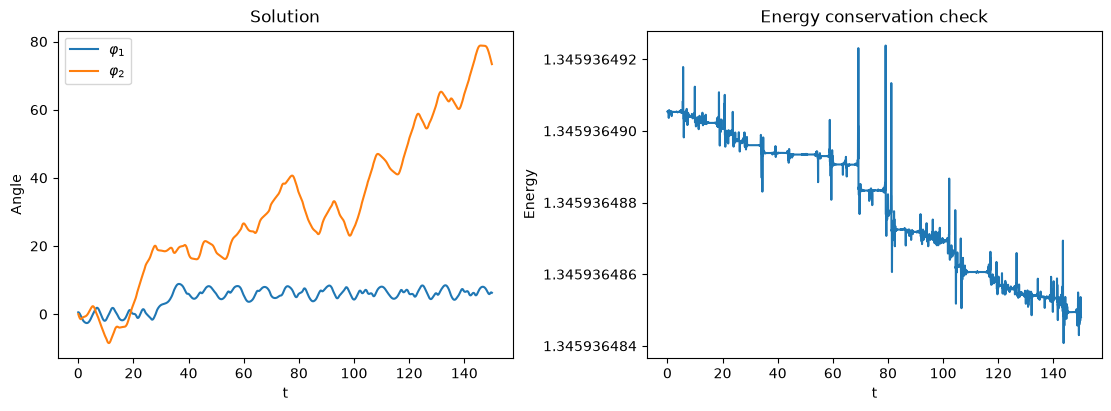

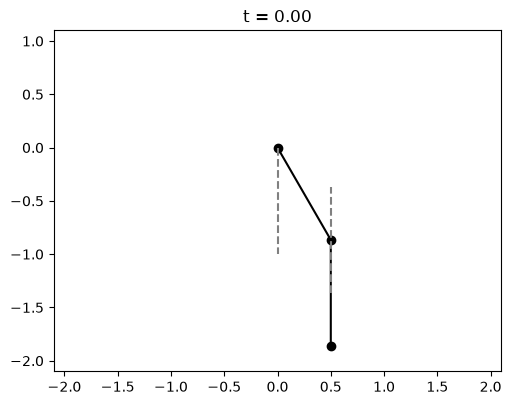

In [4]:
from scipy.integrate import solve_ivp
t0=150.0; m10=1.2; l10=1.0
def double_pendulum_rhs(time,state):
    a1,a2,w1,w2=state; difference=a1-a2
    mass_matrix=np.array([[(m10+1)*l10*l10,l10*np.cos(difference)],
                          [l10*np.cos(difference),1.0]])
    force=np.array([-l10*np.sin(difference)*w2*w2-(m10+1)*l10*np.sin(a1),
                     l10*np.sin(difference)*w1*w1-np.sin(a2)])
    acceleration=np.linalg.solve(mass_matrix,force)
    return [w1,w2,*acceleration]
solution=solve_ivp(double_pendulum_rhs,(0,t0),[np.pi/6,0,0.1,-3],method='DOP853',
                   rtol=1e-10,atol=1e-12,dense_output=True,max_step=0.1)
if not solution.success: raise RuntimeError(solution.message)
times=np.linspace(0,t0,3001); states=solution.sol(times)
a1values,a2values,w1values,w2values=states
energy=(m10+1)*l10*l10*w1values*w1values/2+w2values*w2values/2+l10*w1values*w2values*np.cos(a1values-a2values)-(m10+1)*l10*np.cos(a1values)-np.cos(a2values)
energy_drift=float(np.max(np.abs(energy-energy[0])))
display({'maximum_absolute_energy_drift':energy_drift})
fig,axes=plt.subplots(1,2,figsize=(11,4),layout='constrained')
axes[0].plot(times,a1values,label=r'$\varphi_1$'); axes[0].plot(times,a2values,label=r'$\varphi_2$')
axes[0].set(xlabel='t',ylabel='Angle',title='Solution'); axes[0].legend()
axes[1].plot(times,energy); axes[1].set(xlabel='t',ylabel='Energy',title='Energy conservation check')
axes[1].ticklabel_format(useOffset=False); plt.show()

def show_double_pendulum(time):
    a1,a2=solution.sol(time)[:2]
    p1=l10*np.array([np.sin(a1),-np.cos(a1)]); p2=p1+np.array([np.sin(a2),-np.cos(a2)])
    fig,ax=plt.subplots(figsize=(5,5),layout='constrained')
    ax.plot([0,p1[0],p2[0]],[0,p1[1],p2[1]],'ko-')
    ax.plot([0,0],[0,-1],'--',color='gray'); ax.plot([p1[0],p1[0]],[p1[1]-0.5,p1[1]+0.5],'--',color='gray')
    ax.set(xlim=(-2.1,2.1),ylim=(-2.1,1.1),aspect='equal',title=f't = {time:.2f}'); plt.show()
motion_controls=animate_parameter(show_double_pendulum,0,t0,0,0.2,'t')

## Example: a falling rod with constraints

A uniform rod moves in a uniform gravitational field while its ends slide without friction along two perpendicular walls. Describe its motion and determine how the period depends on the initial conditions.

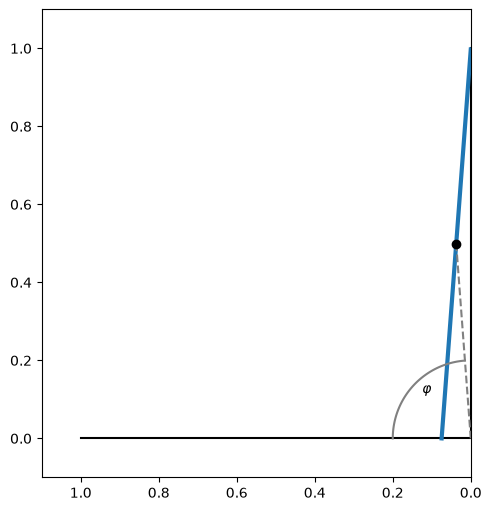

In [5]:
def show_rod(angle):
    tip=np.array([np.cos(angle),np.sin(angle)]); center=tip/2
    fig,ax=plt.subplots(figsize=(5,5),layout='constrained')
    ax.plot([0,0,1],[1,0,0],color='black')
    ax.plot([0,tip[0]],[tip[1],0],lw=3)
    ax.plot([0,center[0]],[0,center[1]],'--',color='gray'); ax.plot(*center,'ko')
    arc=np.linspace(0,angle,100); ax.plot(0.2*np.cos(arc),0.2*np.sin(arc),color='gray')
    ax.text(0.17*np.cos(angle/2),0.17*np.sin(angle/2),r'$\varphi$')
    ax.set(xlim=(1.1,0),ylim=(-0.1,1.1),aspect='equal'); plt.show()
rod_controls=animate_parameter(show_rod,0.01,np.pi/2.1,np.pi/2.1,0.02,'angle')

Using the angle $\varphi$ as the generalized coordinate, the dimensionless Lagrangian is

$$
L=\left(\frac{{\left(\frac{d\varphi }{dt}\right)}^{2}}{3}\right)+\frac{\sin{\varphi} }{2}\tag{20}
$$

The equation of motion is equivalent to that of a pendulum.

## Example: a bead on a circle

A bead of mass $m$ is attached to a uniform hoop of mass $M$, which can slide without friction along a horizontal plane. Motion is confined to a vertical plane in a uniform gravitational field. Describe the system’s motion and period.

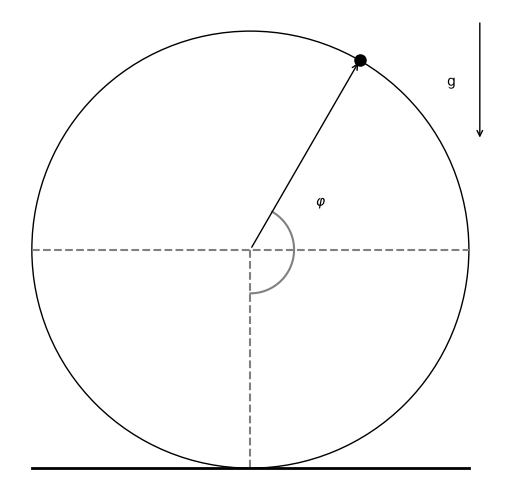

In [6]:
fig,ax=plt.subplots(figsize=(5,5),layout='constrained')
ax.add_patch(plt.Circle((0,0),1,fill=False))
bead=np.array([0.5,np.sqrt(3)/2]); ax.plot(*bead,'ko',ms=8)
ax.annotate('',xy=bead,xytext=(0,0),arrowprops={'arrowstyle':'->'})
arc=np.linspace(-np.pi/2,np.pi/3,100); ax.plot(0.2*np.cos(arc),0.2*np.sin(arc),color='gray')
ax.plot([-1,1],[0,0],'--',color='gray'); ax.plot([0,0],[0,-1],'--',color='gray')
ax.plot([-1,1],[-1,-1],color='black',lw=2)
ax.annotate('',xy=(1.05,0.5),xytext=(1.05,1.05),arrowprops={'arrowstyle':'->'})
ax.text(0.9,0.75,'g'); ax.text(0.3,0.2,r'$\varphi$')
ax.set(xlim=(-1.1,1.15),ylim=(-1.1,1.1),aspect='equal'); ax.axis('off'); plt.show()

$$
L=\frac{1}{2}{\dot{\varphi }}^{2}+\frac{{\dot{x}}^{2}}{2}+\frac{{m\mathbf{v}}^{2}}{2}+m \cos{\varphi} \\ \mathbf{v}=\left(\dot{x}-R \dot{\varphi } \sin{\varphi} ,R \dot{\varphi } \cos{\varphi} \right)\\ \dot{x}+m \left(\dot{x}-\dot{\varphi } \sin{\varphi} \right)=0 \Rightarrow \dot{x} = \frac{m}{m+1}\dot{\varphi } \sin{\varphi} \\ \mathbf{v}=\dot{\varphi } \left(-\frac{1}{m+1}\sin{\varphi} , \cos{\varphi} \right)\\ E=\frac{1}{2}{\dot{\varphi }}^{2}\left(1+m \cos^{2}{\varphi} \right)+\frac{\mu }{2}{\dot{\varphi }}^{2}\sin^{2}{\varphi} -m \cos{\varphi}\tag{21}
$$

## Example: two masses connected by a spring

Two masses $m_1$ and $m_2$ are joined by a massless spring of stiffness $k$. Describe their motion in three dimensions. Hint: reduce the problem to an equivalent one-body system.

[Back to the course contents](https://colab.research.google.com/github/kulinskij-tech/ClassMech/blob/main/ClassMech_Python/classmech_TOC.ipynb)